In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
import zipfile
from zipfile import ZipFile

In [3]:
#%pip install opencv-python

In [4]:
import cv2

In [5]:
os.listdir()

['cnn_binary_image.ipynb', '.ipynb_checkpoints']

In [6]:
os.getcwd()

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/notebooks'

In [7]:
data_dir = "/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data"

os.listdir(data_dir)

['CATDOG', 'cw3_housing_data_part_b.xlsx', 'CATDOG.zip']

In [8]:
path = os.path.join(data_dir, 'CATDOG.zip')

In [9]:
#with zipfile.ZipFile(path, 'r') as data: #extracting the zip folder in the same path
 #   data.extractall(data_dir)
    

In [10]:
os.listdir(data_dir)

['CATDOG', 'cw3_housing_data_part_b.xlsx', 'CATDOG.zip']

In [11]:
#for root, dirs, files in os.walk(data_dir):
 #   print(root)
  ##  for file in files:
    #    print("   └──", file)

In [12]:
way = data_dir + '/CATDOG'

In [13]:
way

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data/CATDOG'

In [14]:
os.listdir(way)

['training_set', 'test_set']

In [15]:
test_dir = way + '/test_set/'
train_dir = way + '/training_set/'

In [16]:
os.listdir(test_dir)

['dogs', 'cats']

In [17]:
os.listdir(train_dir)

['dogs', 'cats']

In [18]:
os.listdir(test_dir+'dogs')[0]

'dog.4159.jpg'

In [19]:
os.listdir(test_dir+'cats')[0]

'cat.4369.jpg'

In [20]:
os.listdir(train_dir+'dogs')[0]

'dog.1753.jpg'

In [21]:
mydog = test_dir+'dogs/'+os.listdir(test_dir+'dogs/')[7]
print(mydog)

/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data/CATDOG/test_set/dogs/dog.4818.jpg


No Color Correction


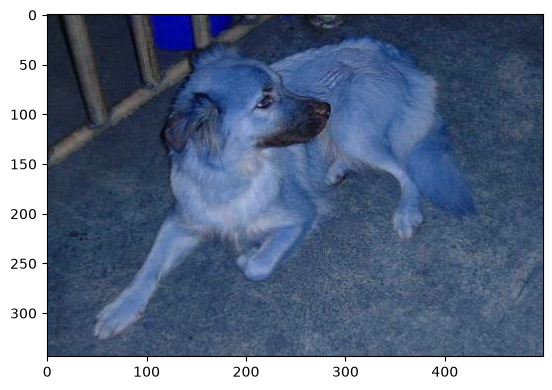

In [22]:
print('No Color Correction')
sample = cv2.imread(mydog)
plt.imshow(sample)


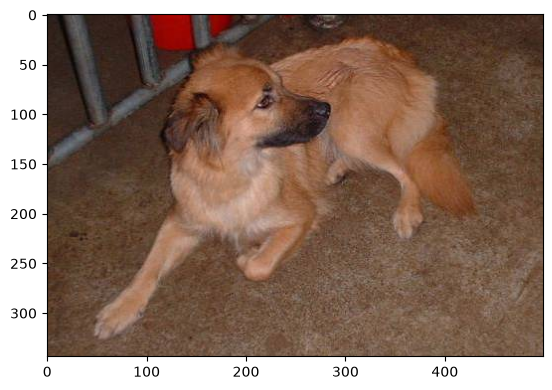

In [23]:
sample = cv2.imread(mydog)
sample = cv2.cvtColor(sample, cv2.COLOR_BGR2RGB)  #color correction
plt.imshow(sample) 

In [24]:
from matplotlib.image import imread #importing imread to replace cv2 for simplicity

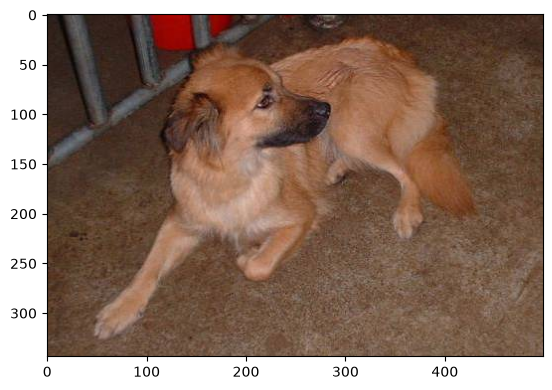

In [25]:
sample_matrix = imread(mydog)
plt.imshow(sample_matrix)   #unlike cv2, we do not have to color correct the images

In [26]:
sample_matrix.shape

(344, 499, 3)

In [27]:
test_dir +'dogs'

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data/CATDOG/test_set/dogs'

In [28]:
shape_x = []                          #creating empty list for width of the images
shape_y = []                          #creating empty list for height of the images
color_channel = []                        #creating empty list for color channel of the images

for i in os.listdir(test_dir+'dogs'):     #running for loop in the dogs folder in test directory
  sample = imread(test_dir + 'dogs/'+i)   #selecting next image everytime    

  shape_x.append(sample.shape[0])               #adding widths in the list
  shape_y.append(sample.shape[1])               #adding hieght in the list
  color_channel.append(sample.shape[2])             #adding color channels in the list

In [29]:
min(shape_x), max(shape_x)

(33, 500)

In [30]:
min(shape_y), max(shape_y)

(92, 500)

In [31]:
min(color_channel), max(color_channel)

(3, 3)

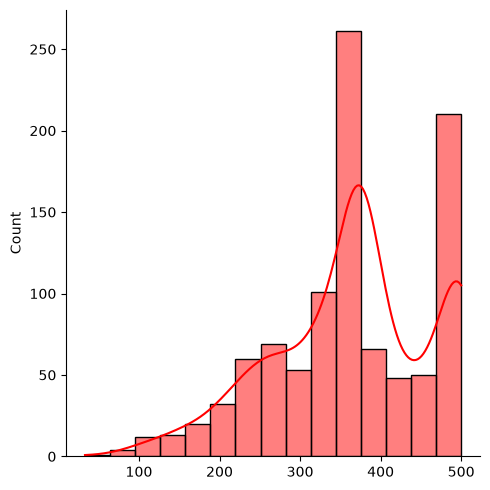

In [32]:
sns.displot(shape_x, bins=15, kde=True, color='red')

In [37]:
#importing other necessary libraries for sequential API model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPool2D, Flatten,BatchNormalization,MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [38]:
#%pip install tensorflow

In [39]:
#making instances of IDG for training and testing

train_IDG=ImageDataGenerator(#width_shift_range= 0.3,  #width manipulation
                         #height_shift_range=0.1,   #heigth manipulation
                         #rotation_range=40,       #rotation enable
                         rescale = 1/255,       #rescaling the images ****VVI****
                         #horizontal_flip =True,   #flipping horizontally able
                         #fill_mode= 'nearest'
                       )
test_IDG=ImageDataGenerator(#width_shift_range= 0.3,
                        #height_shift_range=0.1,
                        rotation_range=40,
                       rescale = 1/255,
                       #horizontal_flip =True,
                       #fill_mode= 'nearest'
                       )


    

In [40]:
imageshape = (100,100)    #defining size of image
batchsize = 100        #defining batch size


In [41]:
print('In the training direcotry, we')

train_generator = train_IDG.flow_from_directory(train_dir,
                                               target_size=imageshape,
                                               color_mode='rgb',
                                               batch_size=batchsize,
                                               class_mode='binary')
print()
print('In the testing direcotry, we')

validation_data_set = test_IDG.flow_from_directory(test_dir,
                                             target_size=imageshape,
                                             color_mode='rgb',
                                             batch_size=batchsize,
                                             class_mode='binary',
                                               shuffle=False)


In the training direcotry, we
Found 8020 images belonging to 2 classes.

In the testing direcotry, we
Found 2000 images belonging to 2 classes.


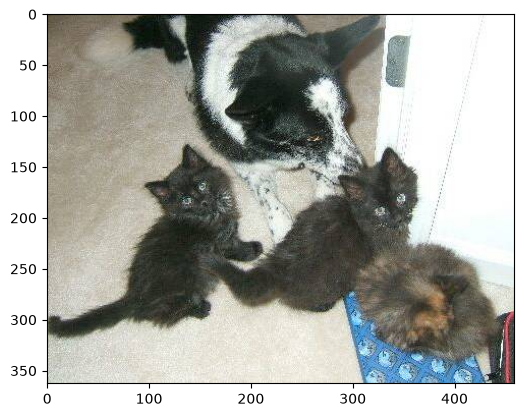

In [42]:
mycat = imread(test_dir+'/cats/cat.4104.jpg')  #reading the image from 'cats' folder and storing under my_cat
plt.imshow(mycat)        #visualising the image

These are some of the possible ways that IDG manipulates the images fed to the model


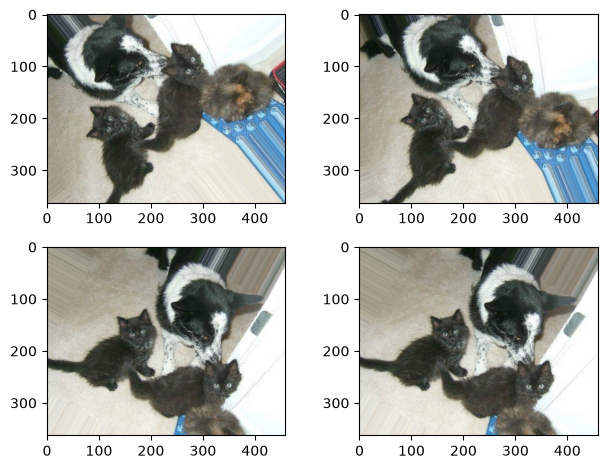

In [46]:
#visualizing what the instance made above does to the input image

fig, ax = plt.subplots(2,2)
plt.tight_layout()

#possibilities
ax[0][0].imshow(test_IDG.random_transform(mycat))
ax[0][1].imshow(test_IDG.random_transform(mycat))
ax[1][1].imshow(test_IDG.random_transform(mycat))
ax[1][0].imshow(test_IDG.random_transform(mycat))

print('These are some of the possible ways that IDG manipulates the images fed to the model')